In [14]:
import numpy as np
import qsharp
import matplotlib.pyplot as plt
qsharp.init(project_root=".")

from qsharp.code import ClassicalPart

N=15 : 100 executions, valeurs min/max = 1/5
N=21 : 100 executions, valeurs min/max = 1/7
N=35 : 100 executions, valeurs min/max = 1/5
   N |  moyenne empirique | borne theorique
---------------------------------------------
  15 |              1.410 | <= 2
  21 |              1.890 | <= 2
  35 |              1.700 | <= 2


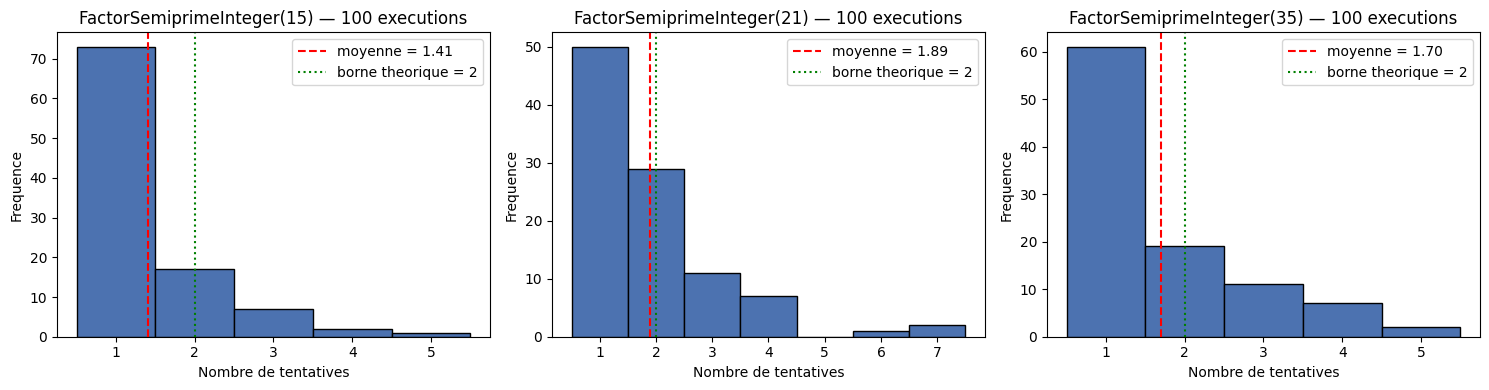

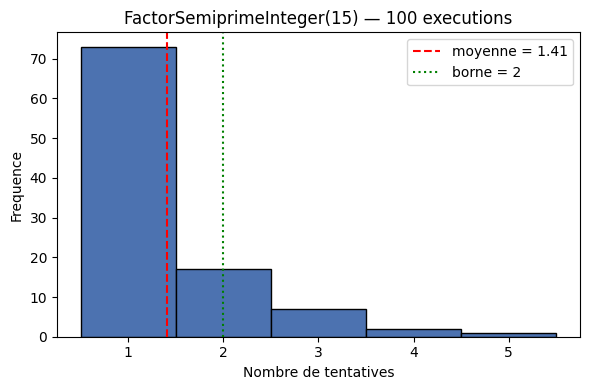

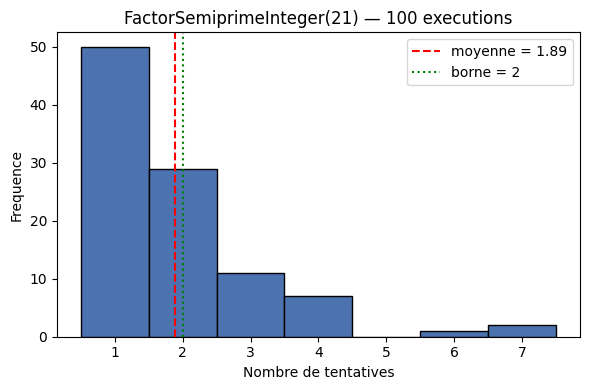

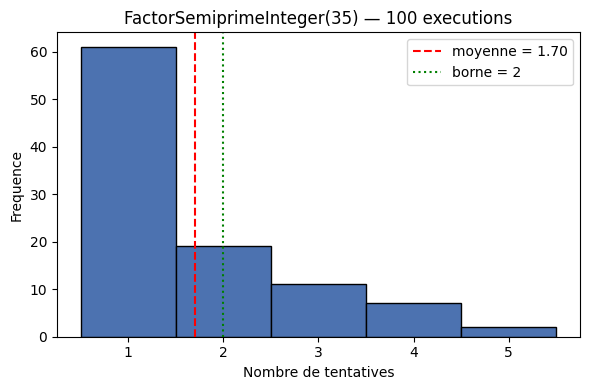

In [19]:
SHOTS = 100
Ns = [15, 21, 35]


resultats = {}
for N in Ns:
    attempts = []
    for _ in range(SHOTS):
        (_facteurs, attempt) = ClassicalPart.FactorSemiprimeInteger(N)
        attempts.append(attempt)
    resultats[N] = np.array(attempts)

for N in Ns:
    print(f"N={N} : {SHOTS} executions, valeurs min/max = "
          f"{resultats[N].min()}/{resultats[N].max()}")

print(f"{'N':>4} | {'moyenne empirique':>18} | borne theorique")
print("-" * 45)
for N in Ns:
    moyenne = resultats[N].mean()
    print(f"{N:>4} | {moyenne:>18.3f} | <= 2")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, N in zip(axes, Ns):
    data = resultats[N]
    moyenne = data.mean()
    bins = np.arange(data.min() - 0.5, data.max() + 1.5, 1)

    ax.hist(data, bins=bins, edgecolor="black", color="#4C72B0")
    ax.axvline(moyenne, color="red", linestyle="--",
               label=f"moyenne = {moyenne:.2f}")
    ax.axvline(2, color="green", linestyle=":",
               label="borne theorique = 2")
    ax.set_xlabel("Nombre de tentatives")
    ax.set_ylabel("Frequence")
    ax.set_title(f"FactorSemiprimeInteger({N}) — {SHOTS} executions")
    ax.legend()

plt.tight_layout()
plt.show()

for N in Ns:
    data = resultats[N]
    moyenne = data.mean()
    bins = np.arange(data.min() - 0.5, data.max() + 1.5, 1)

    plt.figure(figsize=(6, 4))
    plt.hist(data, bins=bins, edgecolor="black", color="#4C72B0")
    plt.axvline(moyenne, color="red", linestyle="--",
                label=f"moyenne = {moyenne:.2f}")
    plt.axvline(2, color="green", linestyle=":", label="borne = 2")
    plt.xlabel("Nombre de tentatives")
    plt.ylabel("Frequence")
    plt.title(f"FactorSemiprimeInteger({N}) — {SHOTS} executions")
    plt.legend()
    plt.tight_layout()
    plt.show()